# 09 - Predictive Modeling 🤖

**Goal:** predict `is_canceled` at booking time, and compare several models.

**Models:**
- Logistic Regression (baseline)
- Random Forest
- XGBoost
- LightGBM

**Metrics:** Precision, Recall, F1, ROC-AUC (accuracy alone is misleading on an imbalanced target).

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from src.config import FEATURES_DATA_PATH, BEST_MODEL_PATH, TARGET, RANDOM_STATE
from src.evaluation import evaluate_model, plot_confusion_matrix, plot_feature_importance

df = pd.read_csv(FEATURES_DATA_PATH)
df.shape

(87139, 39)

## Separate features and target

In [2]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

## Train-test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train.shape, X_test.shape

((69711, 38), (17428, 38))

## One-hot encode categorical columns

In [4]:
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns
print(categorical_cols.tolist())

X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)
X_train.shape, X_test.shape

/tmp/ipykernel_741/2959785371.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns


['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'agent', 'customer_type', 'arrival_quarter']


((69711, 573), (17428, 573))

## Scale features (for Logistic Regression)

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Baseline: Logistic Regression

In [6]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train_scaled, y_train)

results = []
results.append(evaluate_model(lr, X_test_scaled, y_test, model_name='Logistic Regression'))

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.84      0.91      0.87     12632
           1       0.69      0.55      0.61      4796

    accuracy                           0.81     17428
   macro avg       0.77      0.73      0.74     17428
weighted avg       0.80      0.81      0.80     17428

ROC-AUC: 0.8707


## Random Forest

In [7]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(evaluate_model(rf, X_test, y_test, model_name='Random Forest'))

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.87      0.93      0.90     12632
           1       0.78      0.63      0.70      4796

    accuracy                           0.85     17428
   macro avg       0.83      0.78      0.80     17428
weighted avg       0.85      0.85      0.84     17428

ROC-AUC: 0.9100


## XGBoost

In [8]:
xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1
)
xgb.fit(X_train, y_train)
results.append(evaluate_model(xgb, X_test, y_test, model_name='XGBoost'))

--- XGBoost ---
              precision    recall  f1-score   support

           0       0.89      0.92      0.90     12632
           1       0.76      0.69      0.72      4796

    accuracy                           0.85     17428
   macro avg       0.82      0.80      0.81     17428
weighted avg       0.85      0.85      0.85     17428

ROC-AUC: 0.9194


## LightGBM

In [9]:
lgbm = LGBMClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm.fit(X_train, y_train)
results.append(evaluate_model(lgbm, X_test, y_test, model_name='LightGBM'))

--- LightGBM ---
              precision    recall  f1-score   support

           0       0.89      0.92      0.90     12632
           1       0.76      0.70      0.73      4796

    accuracy                           0.86     17428
   macro avg       0.83      0.81      0.82     17428
weighted avg       0.85      0.86      0.85     17428

ROC-AUC: 0.9223


## Model comparison table

In [10]:
results_df = pd.DataFrame(results).set_index('model')
results_df = results_df.sort_values('roc_auc', ascending=False)
results_df

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LightGBM,0.856667,0.761851,0.697039,0.728005,0.922306
XGBoost,0.854602,0.760000,0.689324,0.722939,0.919365
Random Forest,0.849839,0.783355,0.628023,0.697142,0.909955
Logistic Regression,0.808469,0.691640,0.548582,0.611860,0.870684


## Feature importance (best model)

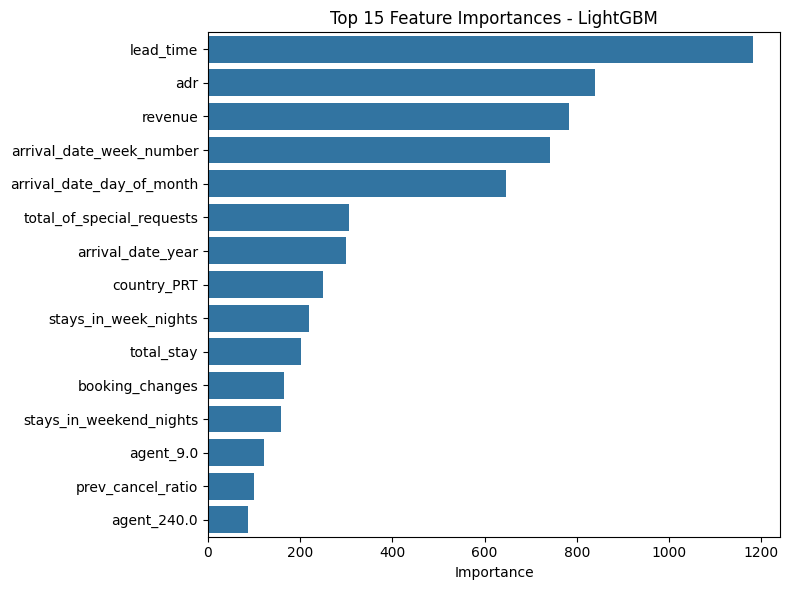

In [11]:
best_model_name = results_df.index[0]
best_model = {'Logistic Regression': lr, 'Random Forest': rf, 'XGBoost': xgb, 'LightGBM': lgbm}[best_model_name]
plot_feature_importance(best_model, X_train.columns, top_n=15, model_name=best_model_name)

## Confusion matrix (best model)

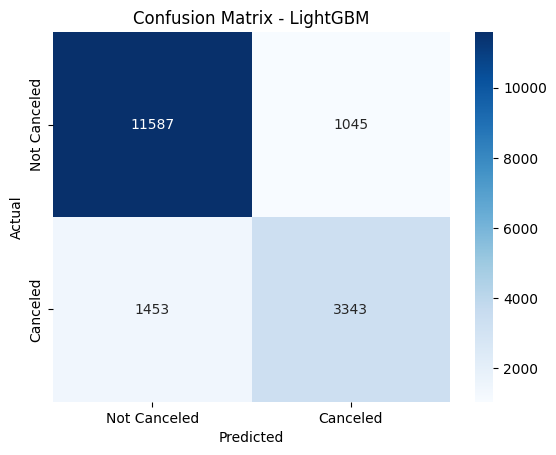

In [12]:
X_eval = X_test_scaled if best_model_name == 'Logistic Regression' else X_test
plot_confusion_matrix(best_model, X_eval, y_test, model_name=best_model_name)

## Save the best model

In [13]:
import joblib
joblib.dump(best_model, BEST_MODEL_PATH)
print(f'Best model: {best_model_name} (ROC-AUC {results_df.loc[best_model_name, "roc_auc"]:.4f})')
print(f'Saved to {BEST_MODEL_PATH}')

Best model: LightGBM (ROC-AUC 0.9223)
Saved to /home/claude/work/hotel-booking-cancellation-analysis/models/best_model.pkl


## Key takeaway

In [14]:
print(results_df.round(4).to_string())
print()
print(f"{best_model_name} wins on ROC-AUC ({results_df.loc[best_model_name, 'roc_auc']:.4f}), "
      f"correctly separating cancellations from completed stays better than the other models tested.")

                     accuracy  precision  recall      f1  roc_auc
model                                                            
LightGBM               0.8567     0.7619  0.6970  0.7280   0.9223
XGBoost                0.8546     0.7600  0.6893  0.7229   0.9194
Random Forest          0.8498     0.7834  0.6280  0.6971   0.9100
Logistic Regression    0.8085     0.6916  0.5486  0.6119   0.8707

LightGBM wins on ROC-AUC (0.9223), correctly separating cancellations from completed stays better than the other models tested.
